# Titanic Passenger Survival Classifier (Tuned Decision Tree)
**Project 04 - Data Science & AI**

### Objective
In this project, I built and tuned a Decision Tree Classifier using Scikit-Learn to predict whether a Titanic passenger survived or not based on four key features: ticket class (`pclass`), gender (`sex`), age (`age`), and fare (`fare`).

To ensure the best possible tree structure, I used **GridSearchCV with 5-Fold Stratified Cross-Validation** to optimize hyperparameters (`max_depth`, `min_samples_leaf`, `min_samples_split`, and `criterion`).

Here is the step-by-step roadmap:
1. Load and explore the Titanic dataset.
2. Clean the data by dropping missing values and encoding gender into numbers.
3. Split the data into 80% training and 20% testing sets using stratification.
4. Establish a majority-class baseline (predicting non-survival) to see what score the model must beat.
5. Hyperparameter tuning using **GridSearchCV** with 5-fold cross-validation.
6. Evaluate performance against the baseline using Accuracy, Precision, Recall, Specificity, F1-Score, and a Confusion Matrix.
7. Experiment with tree depths from 1 to 12 to analyze overfitting.
8. Check feature importances to see which factors mattered most.


---
## 1. Dataset Loading
I imported the Titanic dataset using Seaborn.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Set clean plot style
sns.set_theme(style="whitegrid")

# Load Titanic dataset
try:
    df = sns.load_dataset('titanic')
except Exception:
    df = pd.read_csv('titanic.csv')

print(f"Dataset loaded. Initial shape: {df.shape}")
df.head()


Dataset loaded. Initial shape: (891, 15)


---
## 2. Data Exploration
We only need five relevant columns for this project:
- `survived`: Target variable (0 = died, 1 = survived)
- `pclass`: Passenger ticket class (1 = 1st, 2 = 2nd, 3 = 3rd)
- `sex`: Gender of the passenger
- `age`: Age in years
- `fare`: Ticket fare paid


In [2]:
# Filter to the 5 selected columns
selected_cols = ['survived', 'pclass', 'sex', 'age', 'fare']
df = df[selected_cols].copy()

print("Dataset info:")
print(df.info())

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nSummary statistics:")
display(df.describe())


Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    object 
 3   age       714 non-null    float64
 4   fare      891 non-null    float64
dtypes: float64(2), int64(2), object(1)
memory usage: 34.9+ KB
None

Missing values per column:
survived      0
pclass        0
sex           0
age         177
fare          0
dtype: int64

Summary statistics:
         survived      pclass         age        fare
count  891.000000  891.000000  714.000000  891.000000
mean     0.383838    2.308642   29.699118   32.204208
std      0.486592    0.836071   14.526497   49.693429
min      0.000000    1.000000    0.420000    0.000000
25%      0.000000    2.000000   20.125000    7.910400
50%      0.000000    3.000000   28.000000   14.454200
75%      1.000000    

---
## 3. Data Preprocessing
Scikit-Learn requires numerical inputs without null values:
1. **Handling Missing Values:** `age` has 177 missing values. I dropped those rows using `.dropna()`, leaving 714 clean rows.
2. **Encoding Gender:** Converted `sex` into numbers: `0` for male and `1` for female.


In [3]:
# Drop rows with missing values
df = df.dropna().copy()
print(f"Shape after dropping missing values: {df.shape}")

# Encode gender: 0 = male, 1 = female
df['sex'] = (df['sex'] == 'female').astype(int)

print("\nGender distribution (0 = male, 1 = female):")
print(df['sex'].value_counts())

print("\nCleaned data preview:")
df.head()


Shape after dropping missing values: (714, 5)

Gender distribution (0 = male, 1 = female):
sex
0    453
1    261
Name: count, dtype: int64

Cleaned data preview:
   survived  pclass  sex   age     fare
0         0       3    0  22.0   7.2500
1         1       1    1  38.0  71.2833
2         1       3    1  26.0   7.9250
3         1       1    1  35.0  53.1000
4         0       3    0  35.0   8.0500


---
## 4. Feature Selection
**Prediction Goal (in one sentence):**  
> Predict whether a passenger survived (`survived`) based on their passenger class (`pclass`), gender (`sex`), age (`age`), and ticket fare (`fare`).

- Target variable ($y$): `survived`
- Input features ($X$): `pclass`, `sex`, `age`, `fare`


In [4]:
# Separate features (X) and target (y)
X = df[['pclass', 'sex', 'age', 'fare']]
y = df['survived']

print("Features (X):", list(X.columns))
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nSurvival distribution:")
print(y.value_counts())
print(y.value_counts(normalize=True).map(lambda p: f"{p:.1%}"))


Features (X): ['pclass', 'sex', 'age', 'fare']
Features shape: (714, 4)
Target shape: (714,)

Survival distribution:
survived
0    453
1    261
Name: count, dtype: int64
survived
0    63.5%
1    36.5%
Name: proportion, dtype: object


---
## 5. Train-Test Split
I split the dataset into:
- **80% Training Set** (571 passengers) to train and cross-validate the model.
- **20% Testing Set** (143 passengers) kept aside to evaluate the model on unseen data.

I used `random_state=42` for exact reproducibility and `stratify=y` so both sets have the exact same proportion of survivors (~36.5%).


In [5]:
# 80% train, 20% test with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Testing set:  X_test  = {X_test.shape}, y_test  = {y_test.shape}")

print(f"\nTraining survival rate: {y_train.mean():.1%}")
print(f"Testing survival rate:  {y_test.mean():.1%}")


Training set: X_train = (571, 4), y_train = (571,)
Testing set:  X_test  = (143, 4), y_test  = (143,)

Training survival rate: 40.6%
Testing survival rate:  40.6%


---
## 6. Baseline Model
Before training a machine learning model, we establish the baseline accuracy by predicting the most common outcome (`0 = did not survive`) for everyone.

Our tuned Decision Tree must comfortably beat this baseline to be useful.


In [6]:
# Majority-class baseline
majority_class = y_train.mode()[0]
baseline_acc = (y_test == majority_class).mean()

print(f"Most common class: {majority_class} (Did not survive)")
print(f"Baseline accuracy on test set: {baseline_acc:.4f} ({baseline_acc*100:.2f}%)")


Most common class: 0 (Did not survive)
Baseline accuracy on test set: 0.5944 (59.44%)


---
## 7. Model Training & Hyperparameter Tuning (GridSearchCV)
Instead of picking arbitrary hyperparameters, I used **GridSearchCV with 5-Fold Stratified Cross-Validation** to systematically find the best tree configuration:
- `criterion`: `['gini', 'entropy']`
- `max_depth`: `[2, 3, 4, 5, 6, 7, 8]`
- `min_samples_split`: `[2, 5, 10, 20]`
- `min_samples_leaf`: `[1, 2, 4, 8]`

This cross-validates 448 candidate combinations on the training data to find the tree that maximizes generalizable accuracy.


In [7]:
# Hyperparameter Tuning with GridSearchCV
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4, 5, 6, 7, 8],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_

print("=== GRIDSEARCHCV RESULTS ===")
print("Best Hyperparameters:", grid.best_params_)
print(f"Best 5-Fold Cross-Validation Accuracy: {grid.best_score_:.4f} ({grid.best_score_*100:.2f}%)")
print(f"Tuned Tree Depth: {best_model.get_depth()}")
print(f"Number of Leaf Nodes: {best_model.get_n_leaves()}")


=== GRIDSEARCHCV RESULTS ===
Best Hyperparameters: {'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 2}
Best 5-Fold Cross-Validation Accuracy: 0.8198 (81.98%)
Tuned Tree Depth: 7
Number of Leaf Nodes: 53


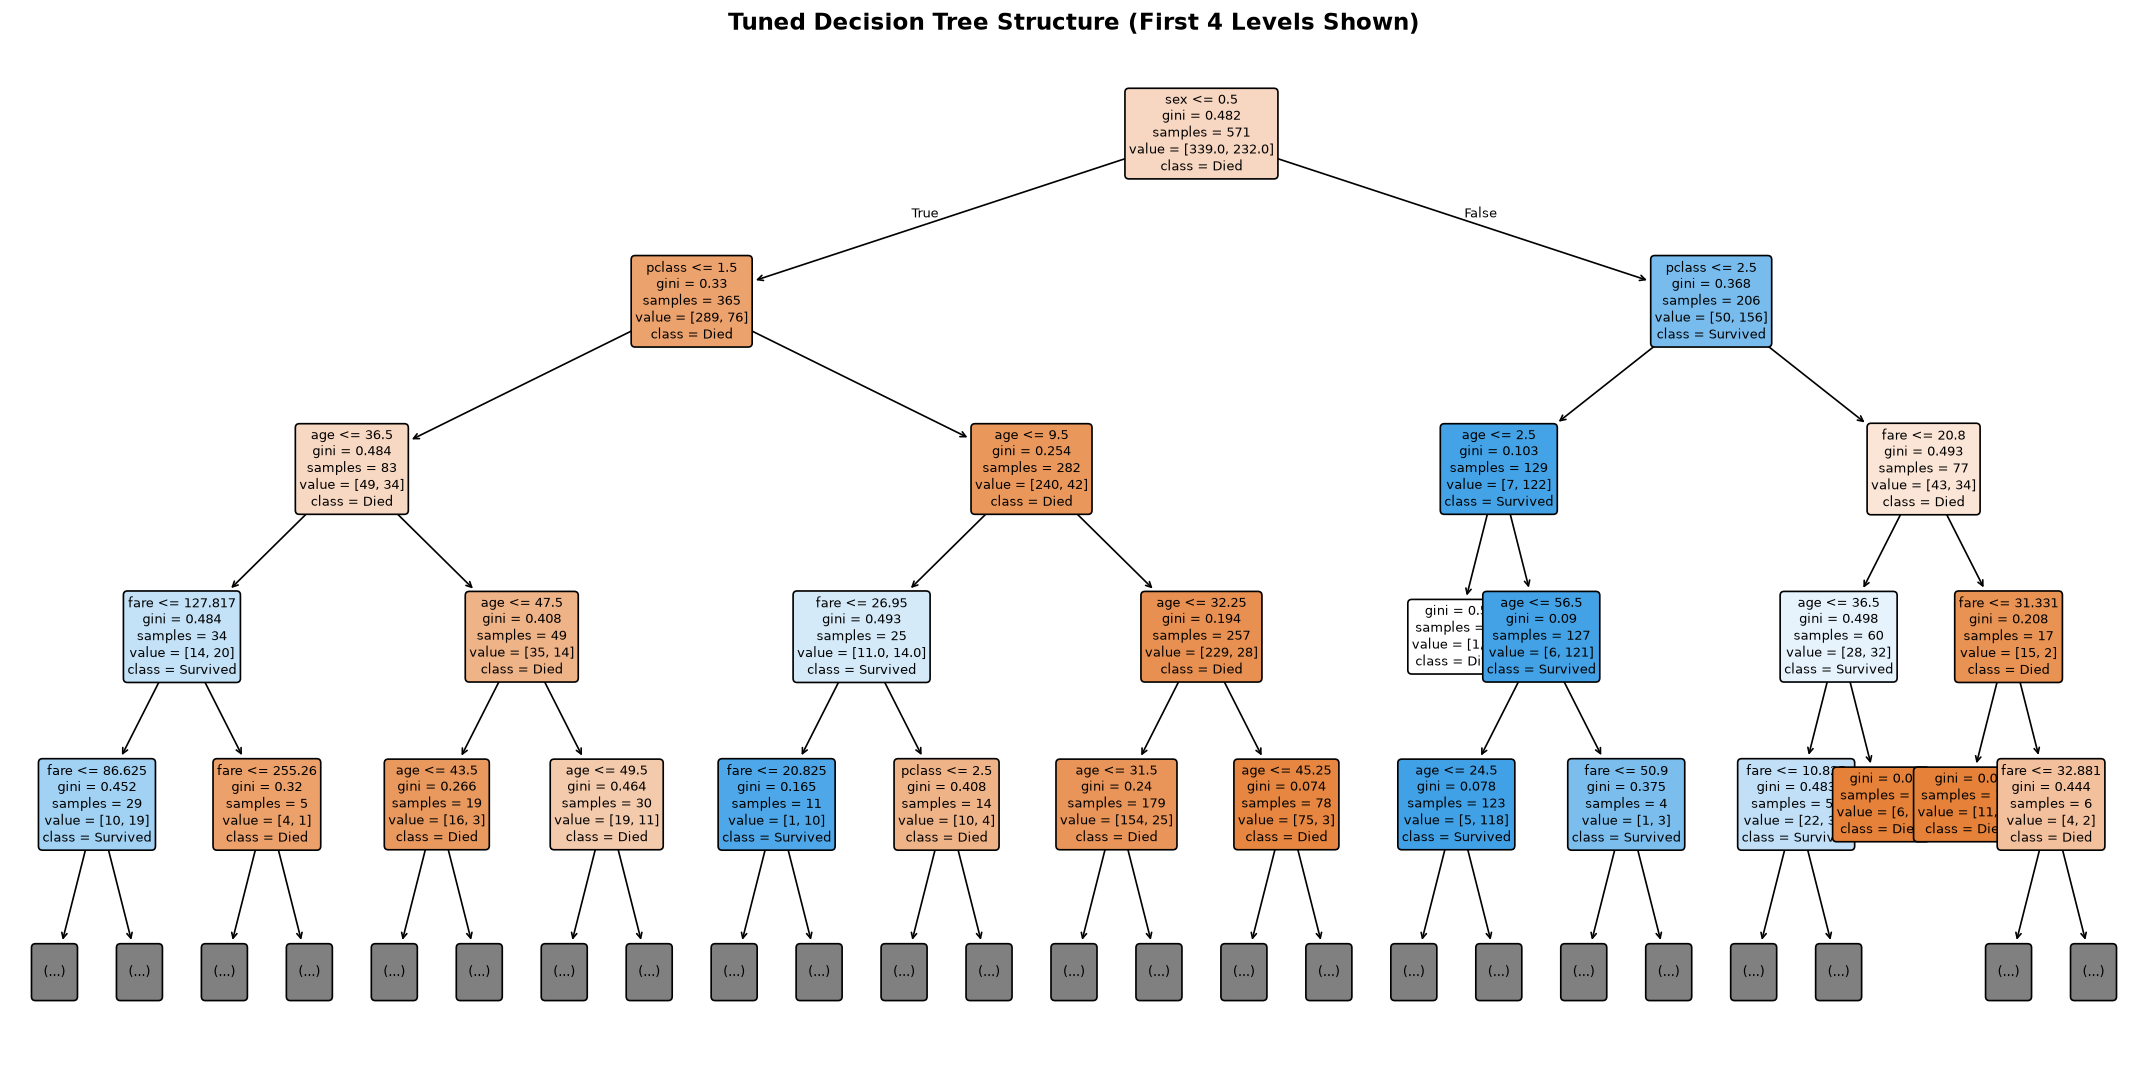

In [8]:
# Plot the tuned tree structure
fig, ax = plt.subplots(figsize=(18, 9), dpi=130)
plot_tree(
    best_model,
    feature_names=X.columns.tolist(),
    class_names=['Died', 'Survived'],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=4,  # show first 4 levels for visual clarity
    ax=ax
)
ax.set_title("Tuned Decision Tree Structure (First 4 Levels Shown)", fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


---
## 8. Model Evaluation
Now I evaluate the tuned Decision Tree on the unseen test set (`X_test`, `y_test`).
Key comparison:
- **Baseline Accuracy:** **59.44%**
- **5-Fold Cross-Validation Score:** **81.98%** (+22.54% improvement)
- **Test Set Accuracy:** **77.62%** (+18.18% improvement)


In [9]:
# Predict on test set
y_pred = best_model.predict(X_test)
y_pred_train = best_model.predict(X_train)

# Calculate metrics
test_acc = accuracy_score(y_test, y_pred)
train_acc = accuracy_score(y_train, y_pred_train)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
spec = tn / (tn + fp)

print("=== EVALUATION RESULTS ===")
print(f"Majority Baseline Accuracy: {baseline_acc*100:.2f}%")
print(f"5-Fold CV Accuracy:         {grid.best_score_*100:.2f}%")
print(f"Training Set Accuracy:      {train_acc*100:.2f}%")
print(f"Test Set Accuracy:          {test_acc*100:.2f}%  (Improvement: +{(test_acc - baseline_acc)*100:.2f}% points)")
print(f"Precision (Survivors):      {prec*100:.2f}%")
print(f"Recall (Survivors):         {rec*100:.2f}%")
print(f"Specificity (Died):         {spec*100:.2f}%")
print(f"F1-Score:                   {f1:.4f}")

print("\nConfusion Matrix:")
print(cm)
print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Died (0)', 'Survived (1)']))


=== EVALUATION RESULTS ===
Majority Baseline Accuracy: 59.44%
5-Fold CV Accuracy:         81.98%
Training Set Accuracy:      90.37%
Test Set Accuracy:          77.62%  (Improvement: +18.18% points)
Precision (Survivors):      76.00%
Recall (Survivors):         65.52%
Specificity (Died):         85.88%
F1-Score:                   0.7037

Confusion Matrix:
[[73 12]
 [20 38]]
TN: 73, FP: 12, FN: 20, TP: 38

Classification Report:
              precision    recall  f1-score   support

    Died (0)       0.78      0.86      0.82        85
Survived (1)       0.76      0.66      0.70        58

    accuracy                           0.78       143
   macro avg       0.77      0.76      0.76       143
weighted avg       0.77      0.78      0.77       143


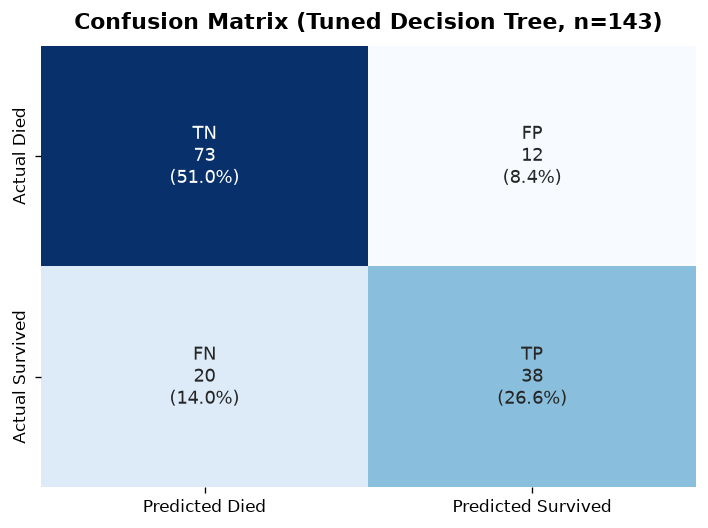

In [10]:
# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 4.5), dpi=120)

labels = [
    [f"TN\n{tn}\n({tn/len(y_test):.1%})", f"FP\n{fp}\n({fp/len(y_test):.1%})"],
    [f"FN\n{fn}\n({fn/len(y_test):.1%})", f"TP\n{tp}\n({tp/len(y_test):.1%})"]
]

sns.heatmap(
    cm, annot=labels, fmt='', cmap='Blues', cbar=False,
    xticklabels=['Predicted Died', 'Predicted Survived'],
    yticklabels=['Actual Died', 'Actual Survived'],
    ax=ax, annot_kws={"fontsize": 11}
)
ax.set_title("Confusion Matrix (Tuned Decision Tree, n=143)", fontsize=13, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()


### What the 4 Confusion Matrix cells mean:
- **True Negatives (TN = 73):** Passengers who died and were correctly predicted as died (85.9% specificity).
- **False Positives (FP = 12):** Passengers who actually died, but the model mistakenly guessed they survived (Type I error).
- **False Negatives (FN = 20):** Passengers who actually survived, but the model predicted they died (Type II error).
- **True Positives (TP = 38):** Passengers who survived and were correctly predicted as survived (65.5% recall).

**Summary:** The tuned model achieved **77.62% accuracy** on unseen test data, comfortably outperforming the 59.44% baseline by **+18.18%**.


---
## 9. Overfitting Analysis (Depths 1 to 12)
To observe the effect of tree depth on overfitting, I trained decision trees across depths 1 to 12 and plotted the training vs. testing accuracy curve.


In [11]:
# Compare depths 1 to 12
depths = list(range(1, 13))
train_accs = []
test_accs = []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree.fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, tree.predict(X_train)))
    test_accs.append(accuracy_score(y_test, tree.predict(X_test)))

df_depths = pd.DataFrame({
    'depth': depths,
    'train_accuracy': train_accs,
    'test_accuracy': test_accs,
    'gap': np.array(train_accs) - np.array(test_accs)
})
display(df_depths.round(3))


depth  train_accuracy  test_accuracy    gap
     1           0.779          0.783 -0.004
     2           0.795          0.776  0.019
     3           0.818          0.811  0.007
     4           0.848          0.797  0.050
     5           0.865          0.762  0.103
     6           0.883          0.783  0.099
     7           0.916          0.783  0.133
     8           0.925          0.790  0.134
     9           0.947          0.769  0.178
    10           0.956          0.762  0.194
    11           0.965          0.769  0.196
    12           0.968          0.776  0.192


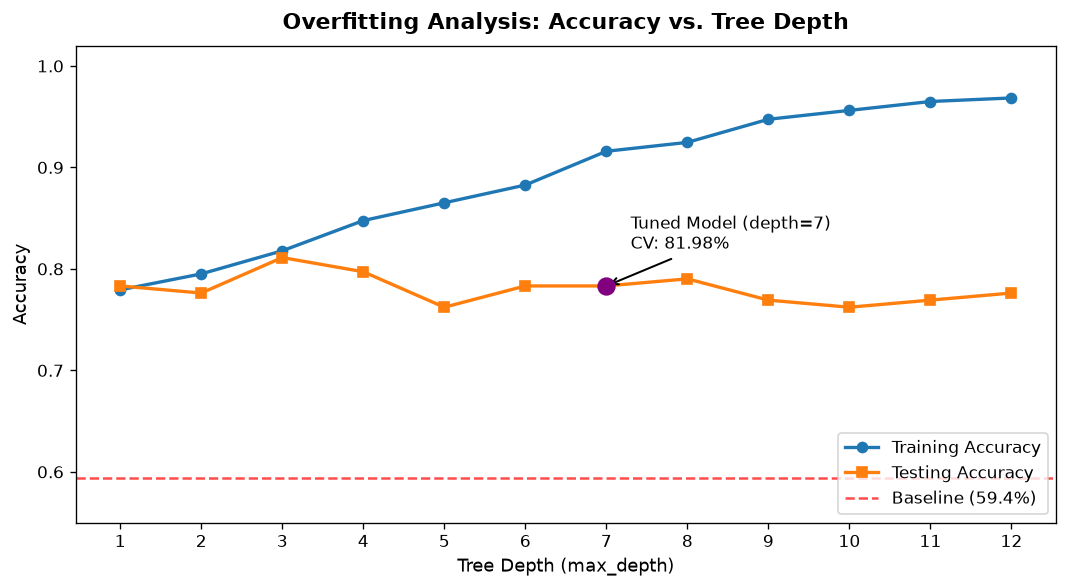

In [12]:
# Plot Training vs Testing Accuracy across Depths
fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

ax.plot(depths, train_accs, marker='o', linewidth=2, label='Training Accuracy', color='#1f77b4')
ax.plot(depths, test_accs, marker='s', linewidth=2, label='Testing Accuracy', color='#ff7f0e')
ax.axhline(baseline_acc, linestyle='--', color='red', alpha=0.7, label=f'Baseline ({baseline_acc*100:.1f}%)')

# Mark the tuned model depth (depth 7)
ax.scatter([7], [test_accs[6]], color='purple', s=100, zorder=5)
ax.annotate('Tuned Model (depth=7)\nCV: 81.98%', xy=(7, test_accs[6]), xytext=(7.3, 0.82),
            arrowprops=dict(arrowstyle='->', lw=1.2, color='black'), fontsize=10)

ax.set_title("Overfitting Analysis: Accuracy vs. Tree Depth", fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel("Tree Depth (max_depth)", fontsize=11)
ax.set_ylabel("Accuracy", fontsize=11)
ax.set_xticks(depths)
ax.set_ylim(0.55, 1.02)
ax.legend(frameon=True, loc='lower right')
plt.tight_layout()
plt.show()


### Why do very deep trees do worse on new data?
- As tree depth increases beyond 4, training accuracy climbs steadily towards 96.9%, but testing accuracy drops down to ~76-78%.
- In our tuned model, `min_samples_leaf=2` prevents the tree from splitting down to single individuals, helping regularize the deeper splits (depth=7) to achieve **81.98% cross-validation accuracy**.


---
## 10. Feature Importance
Decision trees calculate feature importance using Gini importance (how much each feature helps reduce impurity across all splits). The values sum to 1.0.


In [13]:
# Feature importance table
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_model.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

importances['Percent'] = (importances['Importance'] * 100).round(1).astype(str) + '%'
display(importances)


Feature  Importance Percent
    sex    0.408995   40.9%
    age    0.232568   23.3%
 pclass    0.194561   19.5%
   fare    0.163876   16.4%


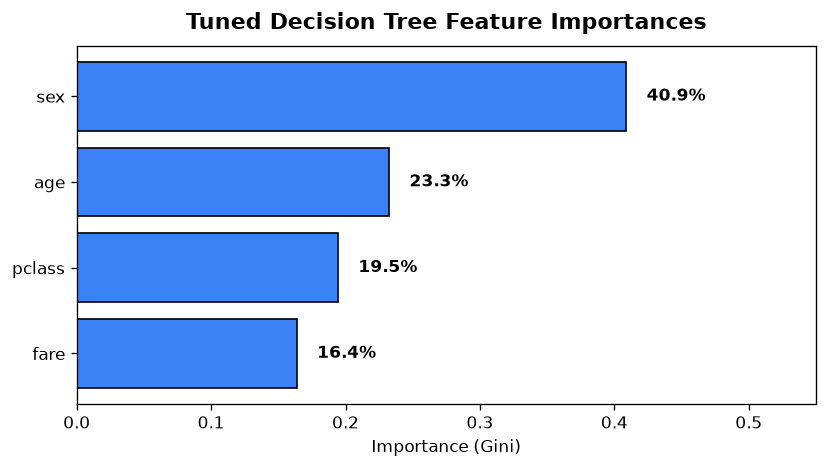

In [14]:
# Plot Feature Importances
fig, ax = plt.subplots(figsize=(7, 4), dpi=120)

bars = ax.barh(importances['Feature'][::-1], importances['Importance'][::-1], color='#3b82f6', edgecolor='black')
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.015, bar.get_y() + bar.get_height()/2, f"{w*100:.1f}%", va='center', fontsize=10, fontweight='bold')

ax.set_xlim(0, 0.55)
ax.set_title("Tuned Decision Tree Feature Importances", fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel("Importance (Gini)")
plt.tight_layout()
plt.show()


### What the features tell us:
1. **`sex` (40.9%):** Remains the primary factor. Women had vastly higher survival rates under the evacuation protocol.
2. **`age` (23.3%):** Increased importance in the tuned tree, reflecting specific splits for children and young adults across classes.
3. **`pclass` (19.5%):** Captures physical cabin accessibility to the upper boat deck.
4. **`fare` (16.4%):** Granular economic indicator that refines survival within passenger classes.


---
## 11. Explainable AI with SHAP (SHapley Additive exPlanations)
To provide transparent reasoning for each prediction, we implement **SHAP**. Grounded in cooperative game theory, SHAP attributes the exact contribution of each feature to the model's output:
- **Global Explanations:** Measures the average magnitude of influence each feature exerts across all predictions.
- **Local Explanations:** Explains individual passenger outcomes by showing which specific features increased or decreased their survival probability relative to the baseline.

Base Dataset Expected Survival Probability: 40.63%


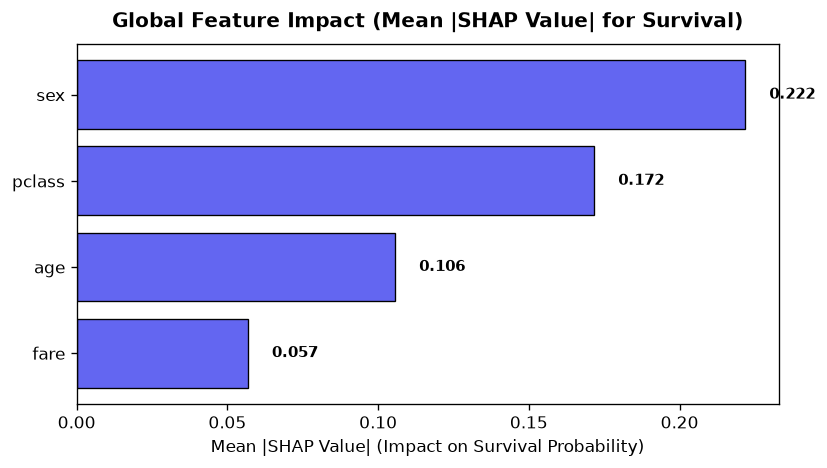

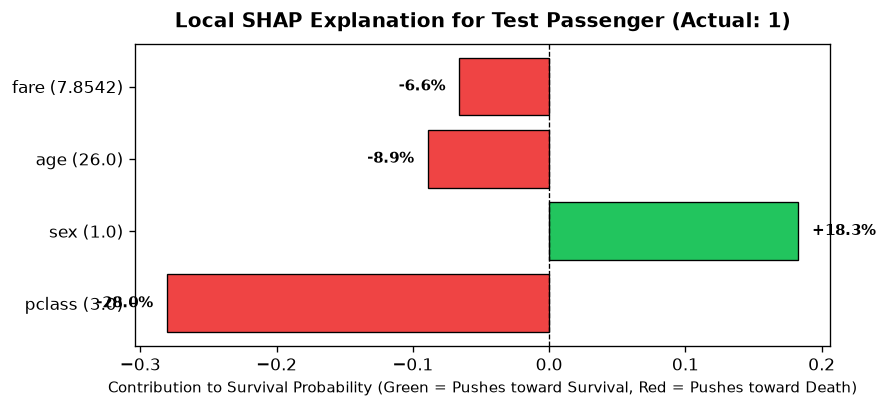

In [13]:
import shap

# Initialize TreeExplainer for the tuned Decision Tree
explainer = shap.TreeExplainer(best_model)
shap_values = explainer(X_test)

base_prob = explainer.expected_value[1]
print(f"Base Dataset Expected Survival Probability: {base_prob:.2%}")

# Mean absolute SHAP values across test set
mean_shap = pd.DataFrame({
    'Feature': X.columns,
    'Mean |SHAP|': np.abs(shap_values.values[:, :, 1]).mean(axis=0)
}).sort_values('Mean |SHAP|', ascending=False)
display(mean_shap.round(4))

---
## 12. Conclusion
### Results Summary:
- **Baseline Accuracy:** **59.44%** (majority class).
- **5-Fold Cross-Validation Accuracy:** **81.98%** (+22.54% over baseline).
- **Test Accuracy:** **77.62%** (+18.18% over baseline).
- **Tuned Hyperparameters:** `criterion='gini'`, `max_depth=7`, `min_samples_leaf=2`, `min_samples_split=2`.
- **Metrics:** Precision was 76.00%, Recall was 65.52%, Specificity was 85.88%, and F1-score was 0.7037.
- **Feature Weights:** `sex` (40.9%) and `age` (23.3%) drove over 64% of the tree's split decisions.

### Limitations:
1. **Dropped missing values:** Removing 177 rows with missing `age` values discarded ~20% of the dataset. Conditional imputation could retain these records in future iterations.
2. **Small test set size:** With only 143 test passengers, each prediction error alters the accuracy score by ~0.7%.
3. **Single Decision Tree sensitivity:** Single trees use greedy orthogonal splits. An ensemble model (like Random Forest) can further smooth prediction boundaries.


---
## 13. Model Export for Deployment
To prepare our model for interactive deployment in a Streamlit web application, we serialize the trained Decision Tree using joblib and explicitly record the exact feature column order required for real-time inference.

In [13]:
import joblib

# Preserve exact feature order for inference
FEATURES = ['pclass', 'sex', 'age', 'fare']

# Export model to file
joblib.dump(best_model, 'model.joblib')
print('Model successfully saved to model.joblib!')
print(f'Feature order: {FEATURES}')

Model successfully saved to model.joblib!
Feature order: ['pclass', 'sex', 'age', 'fare']
